# Simular el modelo SIR con Python
## Clase 1 · Del mecanismo al modelo SIR


## Mini tutorial Python

En esta sección usaremos las herramientas necesarias para implementar el modelo SIR: guardar parámetros, agrupar las condiciones iniciales, definir las ecuaciones, resolverlas y graficar la solución. Ejecuta las celdas en orden.

### 1. Variables y operaciones

El símbolo `=` asigna un valor a un nombre. Python distingue mayúsculas de minúsculas: `I0` e `i0` son nombres diferentes. Usamos `+`, `-`, `*`, `/` y paréntesis para escribir operaciones; las potencias se escriben con `**`.


In [15]:
N = 10_000           # el guion bajo facilita leer el número: 10000
I0 = 10
R_init = 0
S0 = N - I0 - R_init
beta = 0.40
gamma = 1 / 4

print(S0 + I0 + R_init)
print(beta / gamma)


10000
1.6


### 2. Mostrar resultados

El texto se escribe entre comillas. Una f-string inserta el valor de una expresión entre llaves; `:.2f` muestra dos decimales. El prefijo `#` inicia un comentario que Python no ejecuta.


In [16]:
print(f"Población: {N} personas")
print(f"Número reproductivo básico: {beta / gamma:.2f}")


Población: 10000 personas
Número reproductivo básico: 1.60


### 3. Listas y diccionarios

Una **lista** guarda valores en un orden. Los índices empiezan en cero. Podemos desempaquetar sus elementos en varias variables: en el modelo mantendremos siempre el orden `S, I, R`.

Un **diccionario** asocia nombres (claves) con valores. Lo usaremos para reunir los parámetros y acceder a ellos mediante `pars['beta']` y `pars['gamma']`.


In [17]:
y0 = [S0, I0, R_init]
print("Primer elemento:", y0[0])
S, I, R = y0
print(f"S = {S}, I = {I}, R = {R}")

pars = {'beta': beta, 'gamma': gamma}
print("Tasa de transmisión:", pars['beta'])


Primer elemento: 9990
S = 9990, I = 10, R = 0
Tasa de transmisión: 0.4


### 4. Funciones: escribir las ecuaciones

`def` define una función. Los argumentos son los datos que recibe; `return` indica qué devuelve. La sangría delimita el contenido de la función.

Para practicar, calculamos la tasa de nuevas infecciones. Como `S` e `I` representan **personas**, dividimos entre `N`. Después definiremos una función que devuelva las tres derivadas del SIR.


In [18]:
def tasa_infecciones(S, I, beta, N):
    """Devuelve el número de nuevas infecciones por día según el modelo."""
    return beta * S * I / N

nuevas = tasa_infecciones(S0, I0, pars['beta'], N)
print(f"Tasa inicial de nuevas infecciones: {nuevas:.2f} personas/día")


Tasa inicial de nuevas infecciones: 4.00 personas/día


### 5. NumPy: arreglos de tiempos

`import` permite usar una biblioteca; `as np` le da un nombre corto. Un arreglo de NumPy almacena valores numéricos y permite operar sobre todos ellos a la vez.

`np.linspace(inicio, fin, cantidad)` genera puntos igualmente espaciados, incluyendo ambos extremos. Lo usaremos para indicar en qué tiempos queremos obtener la solución.


In [19]:
import numpy as np

tiempos = np.linspace(0, 4, 5)
print("Tiempos:", tiempos)
print("Cuadrados:", tiempos**2)
print("Primer tiempo:", tiempos[0])
print("Último tiempo:", tiempos[-1])


Tiempos: [0. 1. 2. 3. 4.]
Cuadrados: [ 0.  1.  4.  9. 16.]
Primer tiempo: 0.0
Último tiempo: 4.0


### 6. SciPy: resolver una ecuación diferencial

`solve_ivp` aproxima la solución de un problema de valor inicial.

$dy/dt=-k y$, con $y(0)=10$.

La función de las derivadas recibe primero el tiempo `t`, después el estado `y` y luego los parámetros adicionales. Aunque esta ecuación no depende explícitamente de `t`, el argumento es parte de la interfaz del integrador.

En la llamada siguiente:

- `[0, 10]` es el intervalo de integración.
- `[10.0]` es la lista de condiciones iniciales.
- `t_eval` contiene los tiempos donde pedimos resultados.
- `args=(0.25,)` pasa el parámetro `k`; la coma crea una tupla de un elemento. En el SIR usaremos `args=(pars,)` para pasar el diccionario.


In [20]:
from scipy.integrate import solve_ivp

def decaimiento(t, y, k):
    return [-k * y[0]]

tiempos = np.linspace(0, 10, 100)
ejemplo = solve_ivp(decaimiento, [0, 10], [10.0],
                    t_eval=tiempos, args=(0.25,))

print("Integración exitosa:", ejemplo.success)
print("Forma de la solución:", ejemplo.y.shape)
valores = ejemplo.y[0]
print(f"Valor final: {valores[-1]:.2f}")


Integración exitosa: True
Forma de la solución: (1, 100)
Valor final: 0.82


El punto permite acceder a los resultados del integrador: `ejemplo.t` contiene los tiempos y `ejemplo.y` contiene una fila por variable. Aquí hay una sola fila; para el SIR habrá tres y podremos escribir `S, I, R = sol.y`.

### 7. Matplotlib: graficar la solución

`plt.subplots` crea una figura (`fig`) y unos ejes (`ax`). Sobre esos ejes dibujamos las curvas y agregamos sus etiquetas. `plt.show()` muestra la gráfica. Para el SIR dibujaremos tres curvas sobre los mismos ejes.


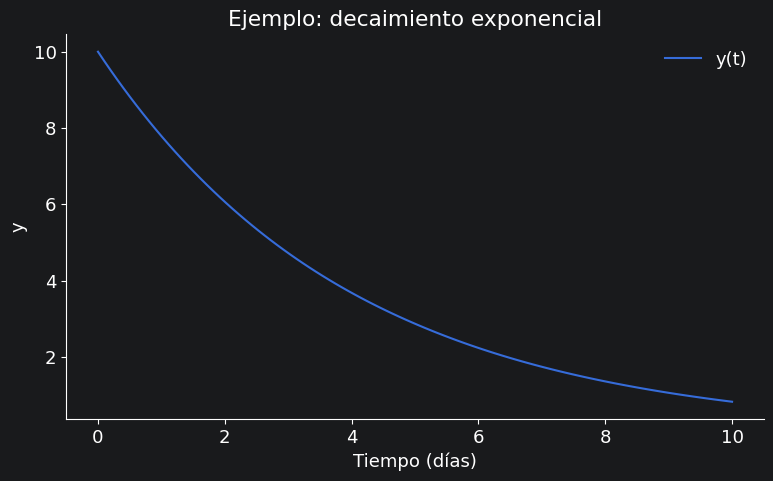

In [22]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'font.size': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

fig_ejemplo, ax_ejemplo = plt.subplots()
ax_ejemplo.plot(ejemplo.t, valores, label='y(t)')
ax_ejemplo.set(xlabel='Tiempo (días)', ylabel='y',
               title='Ejemplo: decaimiento exponencial')
ax_ejemplo.legend(frameon=False)
plt.show()


# Modelo SIR: primera simulación

Consideremos una población de $N=10,000$ personas. Inicialmente hay 10 personas infecciosas y ninguna recuperada:

$I(0)=10,\qquad R(0)=0,\qquad S(0)=N-I(0)-R(0)=9,990.$

Usaremos los siguientes parámetros:
- Tasa de transmisión: $\beta=0.40\ \text{día}^{-1}$.
- Tasa de recuperación: $\gamma=0.25\ \text{día}^{-1}$, que corresponde a un periodo infeccioso medio de $1/\gamma=4$ días.

El número reproductivo básico es
$$
R_0=\frac{\beta}{\gamma}
=\frac{0.40}{0.25}
=1.6.
$$


En una población completamente susceptible, cada persona infecciosa generaría, en promedio, 1.6 nuevas infecciones bajo los supuestos del modelo.

Antes de simular: dado que $R_0>1$ y casi toda la población es susceptible, ¿esperamos que el número de personas infecciosas aumente o disminuya al inicio?



In [23]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

N = 10_000
I0 = 10
R_init = 0
S0 = N - I0 - R_init

beta = 0.40 # transmisión por día
gamma = 1/4 # duración infecciosa media: 4 días
pars = {'beta':beta, 'gamma':gamma}

def sir(t, y, pars):
    beta= pars['beta']
    gamma = pars['gamma']
    S, I, R = y
    dS = -beta * S * I / N
    dI = beta * S * I / N - gamma * I
    dR = gamma * I
    return [dS, dI, dR]


### ¿Qué esperamos observar si $R_0=1.6$?

¿Crecerá inicialmente $I(t)$?
¿Cuándo alcanzará su máximo?
¿Se infectará toda la población?


R₀ = 1.60
S + I + R al final = 10000.000000


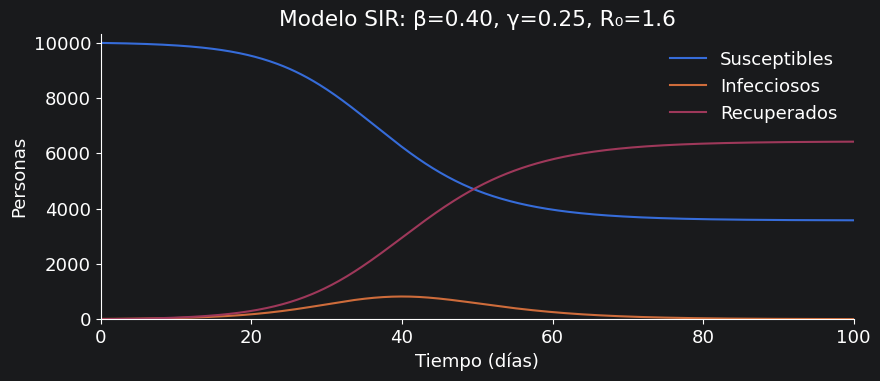

In [29]:
def int_SIR(t_eval, y0, pars):
    sol = solve_ivp(sir, [t_eval[0], t_eval[-1]], y0, t_eval=t_eval, args=(pars,))
    return sol

y0 = [S0, I0, R_init]
t_eval = np.linspace(0, 100, 500)
sol = int_SIR(t_eval, y0, pars)
S, I, R = sol.y
print(f'R₀ = {beta / gamma:.2f}')
print(f'S + I + R al final = {S[-1] + I[-1] + R[-1]:.6f}')


fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sol.t, S, label="Susceptibles")
ax.plot(sol.t, I, label="Infecciosos")
ax.plot(sol.t, R, label="Recuperados")

ax.set(xlabel="Tiempo (días)", ylabel="Personas", title=f"Modelo SIR: β={beta:.2f}, γ={gamma:.2f}, R₀={beta/gamma:.1f}",
    xlim=(0, 100), ylim=(0, N * 1.03),)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Respondemos con el modelo y la simulación

**1. ¿Crecerá inicialmente $I(t)$?**

La ecuación de las personas infecciosas puede escribirse como

$$
\frac{dI}{dt}=I\left(\beta\frac{S}{N}-\gamma\right).
$$

Por tanto, si $I>0$, las infecciones crecen cuando $\beta S/N>\gamma$: las nuevas infecciones superan a las recuperaciones. En este ejemplo,

$$
\beta\frac{S(0)}{N}=0.40\frac{9\,990}{10\,000}=0.3996>0.25=\gamma.
$$

Al inicio hay aproximadamente $3.996$ nuevas infecciones por día y $2.5$ recuperaciones por día: el aumento neto inicial es de $1.496$ personas por día.




In [35]:
# Crecimiento inicial y umbral del pico
numero_reproductivo = pars['beta'] / pars['gamma']
nuevas_iniciales = pars['beta'] * S0 * I0 / N
recuperaciones_iniciales = pars['gamma'] * I0
print(f"Nuevas infecciones por día al inicio: {nuevas_iniciales:.3f}")
print(f"Recuperaciones por día al inicio: {recuperaciones_iniciales:.3f}")
print(f"Aumento neto inicial de I por día: {nuevas_iniciales - recuperaciones_iniciales:.3f}")
print(f"Susceptibles en el pico: {N / numero_reproductivo:,.0f}")

Nuevas infecciones por día al inicio: 3.996
Recuperaciones por día al inicio: 2.500
Aumento neto inicial de I por día: 1.496
Susceptibles en el pico: 6,250


**2. ¿Cuándo alcanzará su máximo?**

El pico ocurre cuando las nuevas infecciones y las recuperaciones se equilibran:

$$
\beta\frac{S}{N}=\gamma
\quad\Longrightarrow\quad
S=\frac{N}{R_0}=6\,250.
$$

La simulación permite encontrar el día: buscamos el índice del mayor valor de $I$. Con estos parámetros, esperamos aproximadamente **821 personas infecciosas alrededor del día 40**. El tiempo calculado depende de la resolución de `t_eval`.


In [37]:
# np.argmax devuelve el índice del mayor valor de un arreglo
indice_pico = np.argmax(I)
print(f"Pico simulado: {I[indice_pico]:.0f} personas en el día {sol.t[indice_pico]:.1f}")


Pico simulado: 821 personas en el día 40.1



**3. ¿Se infectará toda la población?**

No. Al disminuir $S$, la cantidad $\beta S/N$ cae por debajo de $\gamma$: las recuperaciones superan a las nuevas infecciones e $I$ comienza a disminuir, aunque todavía hay personas susceptibles.

Para estimar el tamaño final del brote, extendemos la simulación a 500 días. Con $R(0)=0$, $R$ al final aproxima el total acumulado de personas que pasaron por la infección cuando $I$ ya es prácticamente cero. Esperamos aproximadamente **6 428 personas que habrán pasado por la infección** y **3 572 que permanecerán susceptibles**. El pico de $I$ cuenta infecciones simultáneas; el tamaño final cuenta infecciones acumuladas.

In [38]:
# Una simulación más larga aproxima el final del brote.
# Usamos otros nombres para conservar la simulación y las curvas anteriores.
sol_larga = solve_ivp(sir, [0, 500], y0, args=(pars,),
                      rtol=1e-8, atol=1e-8)
S_final, I_final, R_final = sol_larga.y[:, -1]
infecciones_acumuladas = N - S_final - R_init
print(f"Infecciosos restantes al día 500: {I_final:.6f}")
print(f"Personas que pasaron por la infección: {infecciones_acumuladas:,.0f}")
print(f"Porcentaje de la población infectado durante el brote: {100 * infecciones_acumuladas / N:.1f}%")
print(f"Personas que permanecen susceptibles: {S_final:,.0f}")

Infecciosos restantes al día 500: 0.000000
Personas que pasaron por la infección: 6,428
Porcentaje de la población infectado durante el brote: 64.3%
Personas que permanecen susceptibles: 3,572
